In [3]:
import numpy as np
import os
import glob
from tqdm import tqdm 
import icg_functions as icg

In [9]:
! echo $DATA

/Users/k2585057/Dropbox/PhD/Analysis/Project


In [4]:
data_l = np.sort(glob.glob('/Users/k2585057/Dropbox/PhD/Analysis/Project/PTZ-WILDTYPE/*regtrace_0nan*'))

In [19]:
np.load(data_l[0]).shape

(7694, 4914)

In [27]:
data_l[0].split('_')[0].split('/')[-1] + '_' + data_l[0].split('_') [3]

'PTZ-WILDTYPE-02_BLN'

In [26]:
data_l[0].split('_') [3]

'BLN'

In [5]:
import os
import numpy as np
import pandas as pd

DT = 2.73

rows = []
for i, data in enumerate(tqdm(data_l)):
    X = np.load(data) if isinstance(data, (str, os.PathLike)) else data
    metrics, _ = compute_icg_metrics(X, dt=DT, max_lag_s=20.0)
    rows.append({
        "name":data.split('_')[0].split('/')[-1],
        "cond":data.split('_') [3],
        "trace": i,
        "alpha": metrics["mv_alpha"],
        "beta": metrics["ts_beta"],
        "alpha_r2": metrics["mv_r2"],
        "beta_r2": metrics["ts_r2"]
    })

exponents = pd.DataFrame(rows)
print(exponents.to_string(index=False))

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 30/30 [02:52<00:00,  5.76s/it]

           name  cond  trace    alpha     beta  alpha_r2  beta_r2
PTZ-WILDTYPE-02   BLN      0 1.696092 0.145163  0.999331 0.907368
PTZ-WILDTYPE-02 PTZ05      1 1.717661 0.107020  0.999357 0.849086
PTZ-WILDTYPE-02 PTZ20      2 1.806175 0.074606  0.999707 0.830227
PTZ-WILDTYPE-04   BLN      3 1.680987 0.161798  0.998268 0.906872
PTZ-WILDTYPE-04 PTZ05      4 1.694585 0.131279  0.998714 0.875195
PTZ-WILDTYPE-04 PTZ20      5 1.901782 0.038524  0.999902 0.766277
PTZ-WILDTYPE-05   BLN      6 1.596787 0.183700  0.997512 0.930494
PTZ-WILDTYPE-05 PTZ05      7 1.674474 0.121998  0.998978 0.850855
PTZ-WILDTYPE-05 PTZ20      8 1.825388 0.074321  0.999302 0.794689
PTZ-WILDTYPE-06   BLN      9 1.631271 0.190029  0.997843 0.934157
PTZ-WILDTYPE-06 PTZ05     10 1.724674 0.123036  0.999404 0.879627
PTZ-WILDTYPE-06 PTZ20     11 1.808501 0.115183  0.999590 0.881125
PTZ-WILDTYPE-07   BLN     12 1.480193 0.215287  0.996366 0.956973
PTZ-WILDTYPE-07 PTZ05     13 1.684883 0.137134  0.998420 0.860358
PTZ-WILDTY

In [5]:
import os
import json
from pathlib import Path

import numpy as np
import pandas as pd
from tqdm.auto import tqdm

DT = 2.73
SAVE_DIR = Path("icg_plot_data")
SAVE_DIR.mkdir(parents=True, exist_ok=True)


def flatten_output(value, path, records):
    """Store nested outputs as CSV rows: field, array index, value."""

    if isinstance(value, dict):
        for key, item in value.items():
            flatten_output(item, path + [str(key)], records)

    elif isinstance(value, pd.DataFrame):
        # Preserve column values and dataframe index.
        flatten_output(
            value.index.to_numpy(), path + ["dataframe_index"], records
        )
        for column in value.columns:
            flatten_output(
                value[column].to_numpy(),
                path + ["columns", str(column)],
                records,
            )

    elif isinstance(value, pd.Series):
        flatten_output(
            value.index.to_numpy(), path + ["series_index"], records
        )
        flatten_output(value.to_numpy(), path + ["series_values"], records)

    elif isinstance(value, np.ndarray):
        # Array shape lets you reconstruct multidimensional outputs.
        records.append({
            "field": json.dumps(path),
            "kind": "array_shape",
            "index": "",
            "value": json.dumps(list(value.shape)),
        })
        for index in np.ndindex(value.shape):
            flatten_output(
                value[index],
                path + [f"index:{json.dumps(list(index))}"],
                records,
            )

    elif isinstance(value, (list, tuple)):
        records.append({
            "field": json.dumps(path),
            "kind": "sequence_length",
            "index": "",
            "value": len(value),
        })
        for index, item in enumerate(value):
            flatten_output(item, path + [f"item:{index}"], records)

    elif value is None or isinstance(
        value, (str, bool, int, float, np.generic)
    ):
        records.append({
            "field": json.dumps(path),
            "kind": "value",
            "index": "",
            "value": value.item() if isinstance(value, np.generic) else value,
        })

    else:
        raise TypeError(
            f"Cannot save output at {path}: {type(value).__name__}. "
            "This output needs a specific conversion."
        )


rows = []

for i, source in enumerate(tqdm(data_l)):
    if isinstance(source, (str, os.PathLike)):
        path = Path(source)
        X = np.load(path)

        # Same naming convention, applied to the filename only.
        parts = path.stem.split("_")
        name = parts[0]
        cond = parts[3] if len(parts) > 3 else "unknown"
        source_name = str(path)
    else:
        X = np.asarray(source)
        name = f"animal_{i:03d}"
        cond = "unknown"
        source_name = ""

    # Keep BOTH outputs instead of discarding the second.
    metrics, plot_data = compute_icg_metrics(
        X, dt=DT, max_lag_s=20.0
    )

    records = []
    flatten_output(metrics, ["metrics"], records)
    flatten_output(plot_data, ["plot_data"], records)

    animal_data = pd.DataFrame(records)
    animal_data.insert(0, "name", name)
    animal_data.insert(1, "cond", cond)
    animal_data.insert(2, "trace", i)
    animal_data.insert(3, "dt", DT)
    animal_data.insert(4, "max_lag_s", 20.0)
    animal_data.insert(5, "source", source_name)

    # Trace number prevents overwriting repeated animal/condition names.
    csv_path = SAVE_DIR / f"{name}_{cond}_trace{i:03d}_icg.csv"
    animal_data.to_csv(csv_path, index=False)

    rows.append({
        "name": name,
        "cond": cond,
        "trace": i,
        "alpha": metrics["mv_alpha"],
        "beta": metrics["ts_beta"],
        "alpha_r2": metrics["mv_r2"],
        "beta_r2": metrics["ts_r2"],
        "plot_data_csv": str(csv_path),
    })

exponents = pd.DataFrame(rows)
exponents.to_csv("/Users/k2585057/Dropbox/PhD/Analysis/Project/PTZ-WILDTYPE/exponents_summary.csv", index=False)
print(exponents.to_string(index=False))

0it [00:00, ?it/s]

OSError: Cannot save file into a non-existent directory: '/Users/k2585057/Dropbox/PhD/Analysis/Project/PTZ-WILDTYPE'

In [9]:
exponents.to_csv('/Users/k2585057/Dropbox/PhD/Analysis/Project/PTZ-WILDTYPE/icg_dataframe.csv')

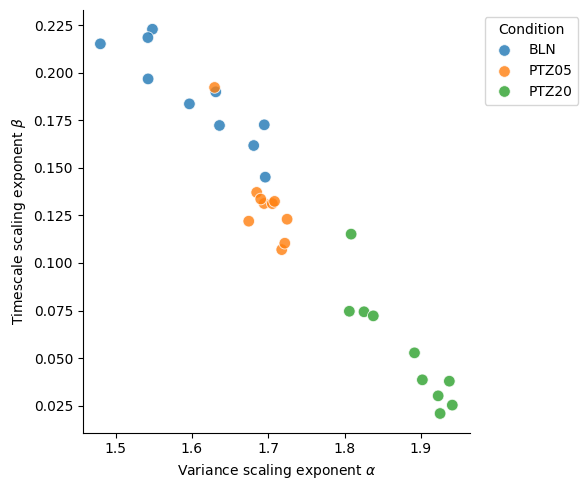

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(6, 5))

sns.scatterplot(
    data=exponents,
    x="alpha",
    y="beta",
    hue="cond",
    palette="tab10",
    s=70,
    alpha=0.8,
    ax=ax,
)

ax.set(
    xlabel=r"Variance scaling exponent $\alpha$",
    ylabel=r"Timescale scaling exponent $\beta$",
)
ax.legend(title="Condition", bbox_to_anchor=(1.02, 1), loc="upper left")
sns.despine()
plt.tight_layout()
plt.show()

In [4]:
import numpy as np
import pandas as pd
from scipy.stats import linregress

# ============================================================
# Fast greedy ICG (Iterative Coarse-Graining) for X: (N, T)
# - Greedy pairing by Pearson correlation at each generation
# - Returns:
#   generations: list[int]
#   labels_by_gen: list[np.ndarray]  (each: (N_original,) cluster id at that generation)
#   mean_traces_by_gen: list[np.ndarray] (each: (n_clusters_gen, T) mean trace per cluster)
#   sizes_by_gen: list[np.ndarray]  (each: (n_clusters_gen,) #cells per cluster)
#
# Notes:
# - This is "fast" in the sense that each generation uses a single BLAS matmul to
#   form the correlation matrix, and greedy pairing runs without sorting edges.
# - Memory: correlation matrix at gen0 is ~N^2 float32 (N=10k -> ~400MB).
# ============================================================

def _zscore_rows(X, eps=1e-6):
    """Row-wise z-score in float32."""
    X = np.asarray(X, dtype=np.float32, order="C")
    mu = X.mean(axis=1, keepdims=True)
    Xc = X - mu
    sd = Xc.std(axis=1, keepdims=True)
    return Xc / (sd + eps)

def _greedy_pairs_from_corr_inplace(C):
    """
    Greedy pairing from correlation matrix C (modified in-place):
      - pick i in order; pair with argmax(C[i]) among remaining.
      - when i,j paired: set rows/cols i,j to -inf so they cannot be reused.
    Returns:
      pairs: (P, 2) int32 with i<j-
      singles: (S,) int32 remaining (if odd n)
    """
    n = C.shape[0]
    pairs = []
    alive = np.ones(n, dtype=bool)

    # diagonal cannot pair with itself
    np.fill_diagonal(C, -np.inf)

    for i in range(n):
        if not alive[i]:
            continue

        j = int(np.argmax(C[i]))  # columns of dead nodes have been set to -inf
        if (j == i) or (not alive[j]) or (not np.isfinite(C[i, j])):
            # couldn't find a partner (should only happen if n==1)
            continue

        a, b = (i, j) if i < j else (j, i)
        pairs.append((a, b))

        # kill both nodes
        alive[i] = False
        alive[j] = False

        # remove them from further consideration: set rows+cols to -inf
        C[i, :] = -np.inf
        C[:, i] = -np.inf
        C[j, :] = -np.inf
        C[:, j] = -np.inf

    pairs = np.asarray(pairs, dtype=np.int32)
    singles = np.where(alive)[0].astype(np.int32)
    return pairs, singles

def icg_greedy_fast(
    X,
    n_gen=None,
    eps=1e-6,
    keep_singletons=True,
    return_gen0=True,
    verbose=False,
):
    """
    Parameters
    ----------
    X : array (N, T)
        Per-cell traces (can be dff, deconvolved, etc).
    n_gen : int or None
        Number of coarse-graining generations to compute (None -> until 1 cluster).
    eps : float
        Stabilizer for z-scoring.
    keep_singletons : bool
        If odd number of units at some generation, keep last as a singleton.
    return_gen0 : bool
        Include generation 0 outputs (labels=0..N-1, mean_traces=X, sizes=1).
    verbose : bool
        Print progress.

    Returns
    -------
    generations : list[int]
    labels_by_gen : list[np.ndarray]      # each (N_original,)
    mean_traces_by_gen : list[np.ndarray] # each (n_clusters_gen, T)
    sizes_by_gen : list[np.ndarray]       # each (n_clusters_gen,)
    """
    X0 = np.asarray(X, dtype=np.float32, order="C")
    N0, T = X0.shape

    # current level representation: units x T are SUMD traces of underlying cells
    X_curr = X0
    sizes_curr = np.ones(X_curr.shape[0], dtype=np.int32)

    # map original cells -> current unit id (starts as identity)
    labels_curr = np.arange(N0, dtype=np.int32)

    generations = []
    labels_by_gen = []
    sum_traces_by_gen = []
    sizes_by_gen = []

    def _append(gen, labels, traces, sizes):
        generations.append(gen)
        labels_by_gen.append(labels.copy())
        sum_traces_by_gen.append(np.asarray(traces, dtype=np.float32))
        sizes_by_gen.append(sizes.copy())

    gen = 0
    if return_gen0:
        _append(gen, labels_curr, X_curr, sizes_curr)

    # how many gens?
    if n_gen is None:
        # until we reach 1 cluster
        max_gen = 10_000  # hard cap safety
    else:
        max_gen = int(n_gen)

    while gen < max_gen:
        n_units = X_curr.shape[0]
        if n_units <= 1:
            break

        gen += 1
        if verbose:
            print(f"[ICG] gen={gen}  n_units={n_units}")

        # 1) correlation matrix for current units (float32)
        Z = _zscore_rows(X_curr, eps=eps)  # (n_units, T)
        C = (Z @ Z.T) / float(T)          # (n_units, n_units) float32

        # 2) greedy pairing on C in-place
        pairs, singles = _greedy_pairs_from_corr_inplace(C)

        # 3) build children lists for new clusters
        if pairs.size == 0 and singles.size == n_units:
            # nothing could be paired (shouldn't happen, but guard)
            if verbose:
                print("[ICG] no pairs formed; stopping.")
            break

        # Decide how to handle singles
        if (not keep_singletons) and (singles.size > 0):
            # drop the singles
            singles = np.empty((0,), dtype=np.int32)

        P = pairs.shape[0]
        S = singles.shape[0]
        n_new = P + S

        # children indices
        a = np.empty(n_new, dtype=np.int32)
        b = np.empty(n_new, dtype=np.int32)

        # pairs first
        if P > 0:
            a[:P] = pairs[:, 0]
            b[:P] = pairs[:, 1]

        # singletons: represent as (s, s) but with weight_b=0
        if S > 0:
            a[P:] = singles
            b[P:] = singles

        # 4) update cluster sizes
        sa = sizes_curr[a].astype(np.float32)
        sb = sizes_curr[b].astype(np.float32)
        if S > 0:
            # zero out sb for singleton rows (so mean stays unchanged)
            sb[P:] = 0.0

        sizes_new = (sa + sb).astype(np.int32)  # (#cells in each new cluster)
        denom = (sa + sb).reshape(-1, 1)        # float32

        # 5) update mean traces (weighted mean of children clusters)
        Xa = X_curr[a]  # (n_new, T)
        Xb = X_curr[b]  # (n_new, T)
        # X_new = (sa.reshape(-1, 1) * Xa + sb.reshape(-1, 1) * Xb) / denom

        X_new = Xa + Xb
        # keep singleton rows unchanged
        if S > 0:
            X_new[P:] = Xa[P:]


        # 6) mapping old units -> new units (for propagating original-cell labels)
        unit_to_new = np.full(n_units, -1, dtype=np.int32)
        unit_to_new[a] = np.arange(n_new, dtype=np.int32)
        if P > 0:
            unit_to_new[b[:P]] = np.arange(P, dtype=np.int32)  # second child of pairs

        # propagate labels for original cells
        labels_curr = unit_to_new[labels_curr]
        if np.any(labels_curr < 0):
            raise RuntimeError("Label propagation failed (found -1). Check singleton handling.")

        # save outputs at this generation
        _append(gen, labels_curr, X_new, sizes_new)

        # advance
        X_curr = X_new
        sizes_curr = sizes_new

    return generations, labels_by_gen, sum_traces_by_gen, sizes_by_gen

#======================
def kurtosis_corr(data):
#======================
    corr = np.corrcoef(data)
    x = corr[np.triu_indices(corr.shape[0], k=1)]
    
    #kurtosis 
    x = np.asarray(x, dtype=np.float64)
    x = x[np.isfinite(x)]
    if x.size < 10:
        return np.nan
    m = x.mean()
    v = x.var()
    if v <= 0:
        return np.nan
    return np.mean((x - m) ** 4) / (v ** 2)

def mean_variance_sum(data):
    if data.size < 10:
        return np.nan
    return float(np.mean(np.var(data, axis=1)))

def mean_autocorr_curve(X, max_lag_frames=10, eps=1e-8):
    X = np.asarray(X, dtype=np.float64)
    if X.ndim != 2:
        return None

    N, T = X.shape
    L = min(max_lag_frames, T - 2)
    if N < 1 or L < 1:
        return None

    ac_sum = np.zeros(L + 1, dtype=np.float64)
    n_used = 0

    for i in range(N):
        x = X[i]

        # safer than removing bad points and compressing time
        if not np.all(np.isfinite(x)):
            continue
        if x.size < L + 2:
            continue

        x = x - x.mean()
        v = x.var(ddof=0)
        if v < eps:
            continue

        x = x / np.sqrt(v)

        ac = np.empty(L + 1, dtype=np.float64)
        ac[0] = 1.0
        for lag in range(1, L + 1):
            ac[lag] = np.dot(x[:-lag], x[lag:]) / (x.size - lag)

        ac_sum += ac
        n_used += 1

    if n_used == 0:
        return None

    return ac_sum / n_used


def timescale(X, max_lag=3.0, dt=1.0):
    max_lag_frames = int(np.floor(max_lag / dt))
    ac_mean = mean_autocorr_curve(X, max_lag_frames=max_lag_frames)
    if ac_mean is None:
        return np.nan

    t = np.arange(ac_mean.size) * dt
    return float(np.trapezoid(ac_mean, t))


def mapp(curr, n_neurons):
    lab = np.full(n_neurons, -1, dtype=int)
    lab[curr.ravel()] = np.repeat(np.arange(len(curr)), curr.shape[1])
    return lab

def label_neuron_bylevel(n_neurons, rng):
    """
    Returns:
      labs: labels per level
      groupings: actual nested neuron groupings per level
    """
    # level 0: pairs
    perm0 = rng.permutation(n_neurons)
    n_used = n_neurons - (n_neurons % 2) #remove odd
    curr_groups = perm0[:n_used].reshape(-1, 2)

    groupings = [curr_groups.copy()]

    # higher levels: pair previous groups, preserving nested structure
    while len(curr_groups) > 1:
        perm = rng.permutation(len(curr_groups))
        #discard odd
        if len(perm) % 2:
            perm = perm[:-1]

        paired = perm.reshape(-1, 2)
        curr_groups = curr_groups[paired].reshape(len(paired), -1)
        groupings.append(curr_groups.copy())

    # labels for compatibility
    labs = []
    for g in groupings:
        lab = np.full(n_neurons, -1, dtype=int)
        for k, row in enumerate(g):
            lab[row] = k
        labs.append(lab)

    return labs, groupings


def wire_A(n_neurons, groupings, t, rng):
    """
    Munn-style hierarchical-modular wiring:
      - level 0 pairs are always connected
      - higher-level edges are added between nested child modules
      - previous edges are never erased
    """
    A = np.zeros((n_neurons, n_neurons), dtype=np.uint8)

    # level 0: force pair edges
    pairs = groupings[0]

    A[pairs[:, 0], pairs[:, 1]] = 1
    A[pairs[:, 1], pairs[:, 0]] = 1

    # higher levels
    for level_idx, groups in enumerate(groupings[1:], start=1):
        P = 1.0 / (float(t) ** level_idx)

        for row in groups:
            half = len(row) // 2

            left = row[:half]
            right = row[half:]

            ii, jj = np.meshgrid(left, right, indexing="ij")
            comb_v = np.column_stack([ii.ravel(), jj.ravel()])

            fwd = (rng.random(comb_v.shape[0]) < P).astype(np.uint8)
            rev = (rng.random(comb_v.shape[0]) < P).astype(np.uint8)

            # ADD edges, never overwrite existing ones
            A[comb_v[:, 0], comb_v[:, 1]] = np.maximum(
                A[comb_v[:, 0], comb_v[:, 1]],
                fwd,
            )
            A[comb_v[:, 1], comb_v[:, 0]] = np.maximum(
                A[comb_v[:, 1], comb_v[:, 0]],
                rev,
            )

    return A

class automata_EI_hiermod:
    def __init__(
        self,
        n_neurons=1000,
        ei_ratio=0.2,
        e_w=0.8,
        i_w=0.8,
        theta=1.5,
        phi=2,
        p_ext=0.001,
        refractory_steps=2,
        dt=0.01,
        seed=0,
    ):
        self.rng = np.random.default_rng(seed)

        self.n = int(n_neurons)
        self.e = int(n_neurons - (n_neurons * ei_ratio))
        self.i = int(n_neurons * ei_ratio)

        self.e_w = float(e_w)
        self.i_w = float(i_w)
        self.theta = float(theta)
        self.phi = float(phi)
        self.p_ext = float(p_ext)
        self.refractory_steps = int(refractory_steps)
        self.dt = float(dt)

        self.labs, self.groupings = label_neuron_bylevel(self.n, rng=self.rng)

        self.A = wire_A(
            n_neurons=self.n,
            groupings=self.groupings,
            t=self.phi,
            rng=self.rng,
        )

        self.A_e = self.A[:self.e, :]
        self.A_i = self.A[self.e:, :]

        self.state = np.zeros(self.n, dtype=np.int16)

    def step(self):
        active = self.state == 1

        inp_e = self.A_e.T @ active[:self.e].astype(np.float32)
        inp_i = self.A_i.T @ active[self.e:].astype(np.float32)

        net = (self.e_w * inp_e) - (self.i_w * inp_i)
        p_net = 1 / (1 + np.exp(-(net - self.theta)))

        quiescent = self.state == 0

        ext_events = self.rng.random(self.n) < self.p_ext
        net_events = self.rng.random(self.n) < p_net

        new_active = quiescent & (ext_events | net_events)

        new_state = np.zeros_like(self.state)

        new_state[active] = 2

        refractory = self.state >= 2
        new_state[refractory] = self.state[refractory] + 1

        done_refrac = new_state > (self.refractory_steps + 1)
        new_state[done_refrac] = 0

        new_state[new_active] = 1

        self.state = new_state

        return (new_state == 1).astype(np.uint8)


#Sanity check for CA
#====================
def run_model(model, T=10.0):
    n_steps = int(T / model.dt)

    spikes = np.zeros((model.n, n_steps), dtype=np.uint8)
    pop_rate = np.zeros(n_steps, dtype=float)

    for t in range(n_steps):
        active = model.step()
        spikes[:, t] = active
        pop_rate[t] = active.mean() / model.dt

    return spikes, pop_rate


def compute_icg_metrics(
    spikes,
    dt,
    max_lag_s=3.0,
    fit_exclude_first=True,
    fit_exclude_last=True,
):
    generations, labels_by_gen, sum_traces_by_gen, sizes_by_gen = icg_greedy_fast(spikes)
    
    rows_by_gen = []

    for gen, Xg, sizes in zip(generations[:-2], sum_traces_by_gen[:-2], sizes_by_gen[:-2]):
        Xg = np.asarray(Xg)
        sizes = np.asarray(sizes)

        mean_cluster_size = float(np.mean(sizes))
        mean_activity = float(np.mean(Xg))
        mean_variance = float(np.mean(np.var(Xg, axis=1)))

        tau = float(timescale(Xg, max_lag=max_lag_s, dt=dt))
        kcorr = float(kurtosis_corr(Xg))

        rows_by_gen.append({
            "gen": int(gen),
            "n_clusters": int(Xg.shape[0]),
            "mean_cluster_size": mean_cluster_size,
            "mean_activity": mean_activity,
            "mean_variance": mean_variance,
            "timescale": tau,
            "corr_kurtosis": kcorr,
        })

    gen_df = pd.DataFrame(rows_by_gen)

    mv0 = float(gen_df.loc[gen_df["gen"].idxmin(), "mean_variance"])
    tau0 = float(gen_df.loc[gen_df["gen"].idxmin(), "timescale"])

    gen_df["mean_variance_l0"] = mv0
    gen_df["timescale_l0"] = tau0

    gen_df["mean_variance_norm"] = gen_df["mean_variance"] / mv0
    gen_df["timescale_norm"] = gen_df["timescale"] / tau0

    gen_df.loc[~np.isfinite(gen_df["mean_variance_norm"]), "mean_variance_norm"] = np.nan
    gen_df.loc[~np.isfinite(gen_df["timescale_norm"]), "timescale_norm"] = np.nan

    mv_alpha, mv_r2, mv_p = safe_loglog_slope(
        gen_df["mean_cluster_size"],
        gen_df["mean_variance"],
        exclude_first=fit_exclude_first,
        exclude_last=fit_exclude_last,
    )
    
    ts_beta, ts_r2, ts_p = safe_loglog_slope(
        gen_df["mean_cluster_size"],
        gen_df["timescale"],
        exclude_first=fit_exclude_first,
        exclude_last=fit_exclude_last,
    )
    
    mv_alpha_norm, mv_r2_norm, mv_p_norm = safe_loglog_slope(
        gen_df["mean_cluster_size"],
        gen_df["mean_variance_norm"],
        exclude_first=fit_exclude_first,
        exclude_last=fit_exclude_last,
    )
    
    ts_beta_norm, ts_r2_norm, ts_p_norm = safe_loglog_slope(
        gen_df["mean_cluster_size"],
        gen_df["timescale_norm"],
        exclude_first=fit_exclude_first,
        exclude_last=fit_exclude_last,
    )

    metric_row = {
        "mv_alpha": mv_alpha,
        "mv_r2": mv_r2,
        "mv_p": mv_p,

        "ts_beta": ts_beta,
        "ts_r2": ts_r2,
        "ts_p": ts_p,

        "mv_alpha_norm": mv_alpha_norm,
        "mv_r2_norm": mv_r2_norm,
        "mv_p_norm": mv_p_norm,

        "ts_beta_norm": ts_beta_norm,
        "ts_r2_norm": ts_r2_norm,
        "ts_p_norm": ts_p_norm,

        "mean_variance_l0": mv0,
        "timescale_l0": tau0,
        "n_icg_gens": int(len(gen_df)),
    }

    return metric_row, gen_df

def model_outs(pars, seed):
    pars = dict(pars)
    T = float(pars.pop("T"))
    smoothe = float(pars.pop("smoothe", 0.05))
    pars["seed"] = int(seed)

    model = automata_EI_hiermod(**pars)
    spikes, pop_rate = run_model(model, T=T)
    
    mean_rate_hz = float(spikes.mean() / float(pars["dt"]))
    pop_rate_mean_hz = float(np.mean(pop_rate))
    pop_rate_std_hz = float(np.std(pop_rate))
    
    frac_silent_frames = float(np.mean(spikes.sum(axis=0) == 0))
    frac_active_neurons = float(np.mean(spikes.sum(axis=1) > 0))

    spikes_icg = exp_smooth_spikes(
        spikes,
        dt=float(pars["dt"]),
        tau=smoothe,
    )
    
    metric_row, gen_df = compute_icg_metrics(
        spikes=spikes_icg,
        dt=float(pars["dt"]),
    )
    
    out = {
        "phi": float(pars['phi']),
        "p_ext": float(pars['p_ext']),
        "seed": int(seed),
    
        "n_neurons": int(pars["n_neurons"]),
        "dt": float(pars["dt"]),
        "T": T,
    
        "theta": float(pars["theta"]),
        "ei_ratio": float(pars["ei_ratio"]),
        "e_w": float(pars["e_w"]),
        "i_w": float(pars["i_w"]),
        "refractory_steps": int(pars["refractory_steps"]),

        "smoothe": smoothe,
    
        "mean_rate_hz": mean_rate_hz,
        "pop_rate_mean_hz": pop_rate_mean_hz,
        "pop_rate_std_hz": pop_rate_std_hz,
        "frac_silent_frames": frac_silent_frames,
        "frac_active_neurons": frac_active_neurons,
    }
    
    out.update(metric_row)
    
    gen_df["phi"] = float(pars["phi"])
    gen_df["p_ext"] = float(pars["p_ext"])
    gen_df["seed"] = int(seed)
    gen_df["n_neurons"] = int(pars["n_neurons"])
    gen_df["smoothe"] = smoothe

    return out, gen_df
    

def safe_loglog_slope(x, y, exclude_first=True, exclude_last=True):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    ok = np.isfinite(x) & np.isfinite(y) & (x > 0) & (y > 0)
    x = x[ok]
    y = y[ok]

    if exclude_first and len(x) > 3:
        x = x[1:]
        y = y[1:]

    if exclude_last and len(x) > 3:
        x = x[:-1]
        y = y[:-1]

    if len(x) < 3:
        return np.nan, np.nan, np.nan

    fit = linregress(np.log10(x), np.log10(y))
    return float(fit.slope), float(fit.rvalue ** 2), float(fit.pvalue)


def sem(x):
    x = pd.Series(x).replace([np.inf, -np.inf], np.nan).dropna()
    if len(x) <= 1:
        return np.nan
    return float(x.std(ddof=1) / np.sqrt(len(x)))



def exp_smooth_spikes(spikes, dt=0.01, tau=0.05):
    """
    Exponential causal smoothing of binary spike matrix.

    Parameters
    ----------
    spikes : array, shape (n_neurons, n_time)
        Binary or count spike raster.
    dt : float
        Simulation timestep in seconds.
    tau : float
        Exponential smoothing time constant in seconds.

    Returns
    -------
    X : array, shape (n_neurons, n_time)
        Smoothed activity traces.
    """
    import numpy as np

    spikes = np.asarray(spikes, dtype=np.float32)

    if tau <= 0:
        return spikes.copy()

    alpha = np.exp(-float(dt) / float(tau))

    X = np.zeros_like(spikes, dtype=np.float32)
    X[:, 0] = spikes[:, 0]

    for t in range(1, spikes.shape[1]):
        X[:, t] = alpha * X[:, t - 1] + spikes[:, t]

    return X